# Practicel ML - KNN

### Full Name : Arshia Goshtasbi

In this Notebook, we will implement KNN for the given dataset. This notebook has 3 phases, in the first phase we explore dataset, in the second phase we preprocess the dataset and in the last phase we implement KNN from scratch and also with sklearn and train it on the dataset.

In [1]:
import numpy as np
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
import seaborn as sns

# Employee-attrition data (the same file as HW3, see data/README.md)
df = pd.read_csv('dataset.csv')

Inspect the first rows of the dataframe

In [2]:
print("First 5 rows of the dataframe:")
print(df.head())

First 5 rows of the dataframe:
   Age Attrition     BusinessTravel  DailyRate              Department  \
0   29        No      Travel_Rarely        592  Research & Development   
1   34        No      Travel_Rarely       1326                   Sales   
2   27        No      Travel_Rarely        954                   Sales   
3   32        No      Travel_Rarely        929                   Sales   
4   50        No  Travel_Frequently       1234  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 7          3  Life Sciences              1            1883   
1                 3          3          Other              1            1478   
2                 9          3      Marketing              1            1965   
3                10          3      Marketing              1             722   
4                20          5        Medical              1            1606   

   ...  RelationshipSatisfaction StandardHo

Calculate the number of samples

In [3]:
num_samples = df.shape[0]
print(f"\nNumber of samples: {num_samples}")



Number of samples: 902


Measure the number of unique values for each column. Note that Attrition is the target column.

In [4]:
print("\nNumber of unique values for each column:")
print(df.nunique())


Number of unique values for each column:
Age                          42
Attrition                     2
BusinessTravel                3
DailyRate                   653
Department                    3
DistanceFromHome             29
Education                     5
EducationField                6
EmployeeCount                 1
EmployeeNumber              902
EnvironmentSatisfaction       4
Gender                        2
HourlyRate                   71
JobInvolvement                4
JobLevel                      5
JobRole                       9
JobSatisfaction               4
MaritalStatus                 3
MonthlyIncome               853
MonthlyRate                 888
NumCompaniesWorked           10
Over18                        1
OverTime                      2
PercentSalaryHike            15
PerformanceRating             2
RelationshipSatisfaction      4
StandardHours                 1
StockOptionLevel              4
TotalWorkingYears            40
TrainingTimesLastYear         

Check if there is a column with less than two unique values. If such a columns exists, remove it!

In [5]:
for col in df.columns:
    if df[col].nunique() < 2:
        df = df.drop(col, axis=1)
        print(f"\nColumn '{col}' removed as it has less than 2 unique values.")



Column 'EmployeeCount' removed as it has less than 2 unique values.

Column 'Over18' removed as it has less than 2 unique values.

Column 'StandardHours' removed as it has less than 2 unique values.


Plot Mean BusinessTravel against Age. Note: Since the BusinessTravel column is categorical, you should first consider another column corresponding to each unique value BusinessTravel takes. For instance, you may assume that if someone does not travel, the value of the column for this person is 0.

In [6]:
business_travel_dummies = pd.get_dummies(df['BusinessTravel'], prefix='BusinessTravel')


In [7]:
df_plot = pd.concat([df['Age'], business_travel_dummies], axis=1)
mean_bt_by_age = df_plot.groupby('Age').mean()


Check if there seems to be a meaningful relationship between people's age and the years they have worked with their current manager. Your result should be a plot.

<Figure size 1200x800 with 0 Axes>

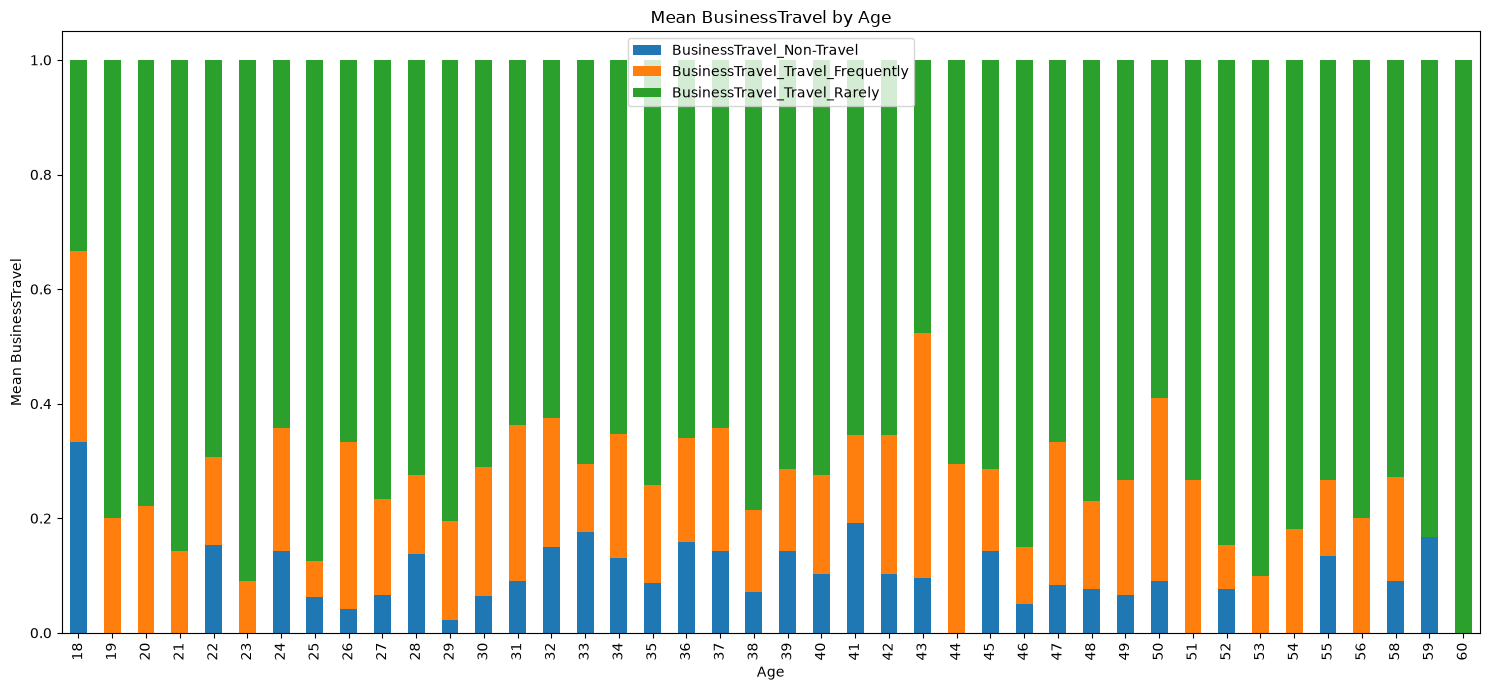

In [8]:
plt.figure(figsize=(12, 8))
mean_bt_by_age.plot(kind='bar', stacked=True, figsize=(15,7))
plt.title('Mean BusinessTravel by Age')
plt.xlabel('Age')
plt.ylabel('Mean BusinessTravel')
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig('business_travel_vs_age.png')

Plot the average MonthlyIncome against the YearsAtCompany. 

In [9]:
print("\nPlot of Mean BusinessTravel against Age is saved as 'business_travel_vs_age.png'")


Plot of Mean BusinessTravel against Age is saved as 'business_travel_vs_age.png'


## Preprocessing

Label encode all categorical columns and split the data into train and test parts. The training part will further splitted into train and validation parts.

In [10]:
le = LabelEncoder()
for col in ['Gender', 'OverTime', 'Attrition']:
    if col in df.columns:
        df[col] = le.fit_transform(df[col])

df = pd.get_dummies(df, drop_first=True)
X = df.drop('Attrition', axis=1)
y = df['Attrition']

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [12]:
# lens of train and validation datasets

# TODO

Split the test and validation dataframe into feature and label part, Attrition columns is the target columns and rest of the columns should be treated as features. (Note that win_or_defeat column is the target column)

In [13]:
# TODO


# Model Implementation From Scratch
  



## How the algorithm works

**We calculate the euclidean distance between a new sample and all points**

**We determine the label of the sample based on the majority vote**

## Key Points:

### Euclidean Distance
**Euclidean distance is defined as the distance between two points**

**Where it's represented by this equation :
$$\sqrt{\sum\limits_{i = 0}^{m-1} (x - y)^2}$$**


In [14]:
class KNN:
    """
    K-Nearest Neighbors classifier.
    """
    def __init__(self, k=3):
        """
        Initialize the KNN classifier.

        Parameters:
        - k (int): Number of neighbors to use.
        """
        self.k = k

    def fit(self, X_train, y_train):
        """
        Fit the model using the training data.

        Parameters:
        - X_train (DataFrame): Training feature vectors.
        - y_train (Series): Training labels.
        """
        self.X_train = X_train.values
        self.y_train = y_train.values

    def euclidean_distance(self, x1, x2):
        """
        Calculate the distance between two data points.

        Parameters:
        - x1 (numpy array): First data point.
        - x2 (numpy array): Second data point.

        Returns:
        - float: Distance between x1 and x2.
        """
        return np.sqrt(np.sum((x1 - x2)**2))

    def predict(self, X_test):
        """
        Predict labels for test data.

        Parameters:
        - X_test (DataFrame): Test feature vectors.

        Returns:
        - numpy array: Predicted labels.
        """
        X_test_np = X_test.values
        y_pred = [self._predict(x) for x in X_test_np]
        return np.array(y_pred)

    def _predict(self, x):
        """
        Predict label for a single data point.

        Parameters:
        - x (numpy array): Test data point.

        Returns:
        - int: Predicted label.
        """
        # Compute distances between x and all examples in the training set
        distances = [self.euclidean_distance(x, x_train) for x_train in self.X_train]
        # Sort by distance and return indices of the first k neighbors
        k_indices = np.argsort(distances)[:self.k]
        # Extract the labels of the k nearest neighbor training samples
        k_nearest_labels = [self.y_train[i] for i in k_indices]
        # Return the most common class label
        most_common = Counter(k_nearest_labels).most_common(1)
        return most_common[0][0]


# Evaluation
  

Define the model and train it.

In [15]:
knn_scratch = KNN(k=5)
knn_scratch.fit(X_train, y_train)

Predict the y_train and y_test values.

In [16]:
y_pred_train_scratch = knn_scratch.predict(X_train)
y_pred_test_scratch = knn_scratch.predict(X_test)

# Sklearn Implementation
  

Define the sklearn knn model and fit to the training data

In [17]:
# TODO
knn_sklearn = KNeighborsClassifier(n_neighbors=5)
knn_sklearn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


Now predict the defined model on test data and return the accuracy

In [18]:
# TODO
y_pred_train_sklearn = knn_sklearn.predict(X_train)
y_pred_test_sklearn = knn_sklearn.predict(X_test)

In [19]:
print("\n--- Results ---")
print("Accuracy of KNN from scratch on training data:", accuracy_score(y_train, y_pred_train_scratch))
print("Accuracy of KNN from scratch on test data:", accuracy_score(y_test, y_pred_test_scratch))
print("\nAccuracy of scikit-learn KNN on training data:", accuracy_score(y_train, y_pred_train_sklearn))
print("Accuracy of scikit-learn KNN on test data:", accuracy_score(y_test, y_pred_test_sklearn))



--- Results ---
Accuracy of KNN from scratch on training data: 0.8210818307905686
Accuracy of KNN from scratch on test data: 0.7624309392265194

Accuracy of scikit-learn KNN on training data: 0.8210818307905686
Accuracy of scikit-learn KNN on test data: 0.7624309392265194


# Thank You


**Thank you for taking your time going through this notebook**

**If you have any feedback please let me know**